# Term Life Insurance Analysis

## Objective

This notebook investigates two things:
1. The relationship between the entry age $x$ of an insured person and the annual net premium $P$ of a term life insurance contract with term $n \in \mathbb{N}$.
2. The relationship between the lifetime $\{0, 1, ..., n\}$ of the contract and the prospective reserve ${}_tV(x)$ at times $t \in \{0, 1, ..., n\}$ depending on the entry age $x$ and the annual premium $P$ of the contract.

The analysis compares the resulting premiums for male and female policyholders and the prospective reserves for male and female for a contract with a 50 year old individual.

## Methodology

The calculations are performed using the custom Python classes `MortalityTable` and `TermLifeInsurance`.

The net premium is determined according to the equivalence principle:

$$
EPV_{\text{Benefits}}(x) = EPV_{\text{Premiums}}(x)
$$

with

$$
EPV_{\text{Benefits}}(x) = C \cdot \sum\limits_{k=1}^{n} v^{k} \cdot {}_{k-1|}q_x
$$

and

$$
EPV_{\text{Premiums}}(x) = P \cdot \sum\limits_{k=0}^{n-1} v^{k} \cdot {}_{k}p_{x}
$$

where ${}_{k-1|}q_x$ is the probability that the individual dies with age $x+k-1$ and ${}_{k}p_{x}$ is the probability that the individual survives until age $x+k$ when being $x$ years old at the beginning of the contract.

The prospective reserve at time $t \in \{0, 1, ..., n\}$ is calculated via the formula:

$$
{}_tV(x) = EPV_{\text{Benefits}}(x+t) - EPV_{\text{Premiums}}(x+t) = C \cdot \sum\limits_{k=1}^{n-t} v^{k} \cdot {}_{k-1|}q_{x+t} - P \cdot \sum\limits_{k=0}^{n-t-1} v^{k} \cdot {}_{k}p_{x+t}
$$

## Model assumptions

- Fixed insurance term of $n=10$ years
- Constant interest rate of $i=3\%$ so $v=\frac{1}{1.03}$
- Death benefit of $C=100000$
- Annual premiums $P$ are due at the start of each year (in advance)
- Death benefit is paid in the end of the year of death
- The reserve is calculated immediately before the premium payment at each policy anniversary
- No expenses, commissions or additional policyholder benefits

The mortality assumptions are based on the mortality data documented in `DATA_SOURCE.md`.

In [1]:
# Import libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mortality import MortalityTable
from products import TermLifeInsurance

In [2]:
# Load mortality data
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (PROJECT_ROOT / "data" / "processed" / "mortality_table.csv")

df = pd.read_csv(DATA_PATH)

mortality_table = MortalityTable(df)

In [3]:
# Create insurance
TERM = 10
INTEREST_RATE = 0.03
DEATH_BENEFIT = 100000
# Age for reserve calculation of a specific contract
AGE_INDIVIDUAL = 50

insurance = TermLifeInsurance(term=TERM, interest_rate=INTEREST_RATE, death_benefit=DEATH_BENEFIT, mortality_table=mortality_table)

In [4]:
## Net Premium Analysis ##

# Restrict analysis to ages between 20 and 70
start_age = 20
end_age = 70

results = []

# Generate results
for age in range(start_age, end_age + 1):
    premium_male = insurance.net_premium(age=age, gender="male")
    premium_female = insurance.net_premium(age=age, gender="female")
    results.append({
        "age": age,
        "premium_male": premium_male,
        "premium_female": premium_female})

results_df = pd.DataFrame(results)
results_df.head()

,age,premium_male,premium_female
0,20,44.434416,19.333181
1,21,44.890191,19.822770
2,22,45.862468,20.518163
3,23,47.020325,21.798390
4,24,48.938583,23.322143


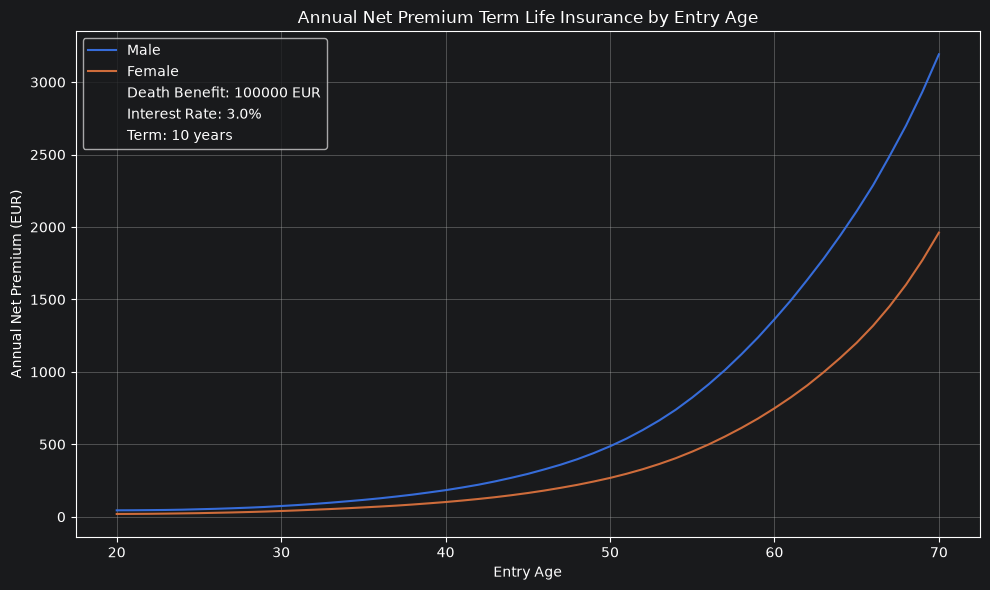

In [5]:
# Visualize results
plt.figure(figsize=(10, 6))

plt.plot(results_df["age"], results_df["premium_male"], label="Male")

plt.plot(results_df["age"], results_df["premium_female"], label="Female")

plt.title("Annual Net Premium Term Life Insurance by Entry Age")

plt.xlabel("Entry Age")
plt.ylabel("Annual Net Premium (EUR)")

# Create invisible lines to display parameters in legend
plt.axhline(y=0, color='none', label=f"Death Benefit: {DEATH_BENEFIT} EUR")
plt.axhline(y=0, color='none', label=f"Interest Rate: {INTEREST_RATE * 100}%")
plt.axhline(y=0, color='none', label=f"Term: {TERM} years")

plt.legend()
plt.grid(True)

plt.tight_layout()

# safe figure
FIGURE_PATH = (PROJECT_ROOT / "reports" / "figures" / "net_premium_TLI_by_age.png")
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")

plt.show()

In [6]:
## Prospective Reserve Analysis ##

results_reserve = []

# Generate results
for year in range(0, TERM + 1):
    reserve_male = insurance.prospective_reserve(age=AGE_INDIVIDUAL, gender="male", t=year)
    reserve_female = insurance.prospective_reserve(age=AGE_INDIVIDUAL, gender="female", t=year)
    results_reserve.append({
        "year": year,
        "reserve_male": reserve_male,
        "reserve_female": reserve_female})

results_reserve_df = pd.DataFrame(results_reserve)
results_reserve_df.head()

,year,reserve_male,reserve_female
0,0,0.000000,0.000000
1,1,183.041355,100.195355
2,2,349.891566,185.456325
3,3,471.850582,257.212270
4,4,560.980092,307.488925


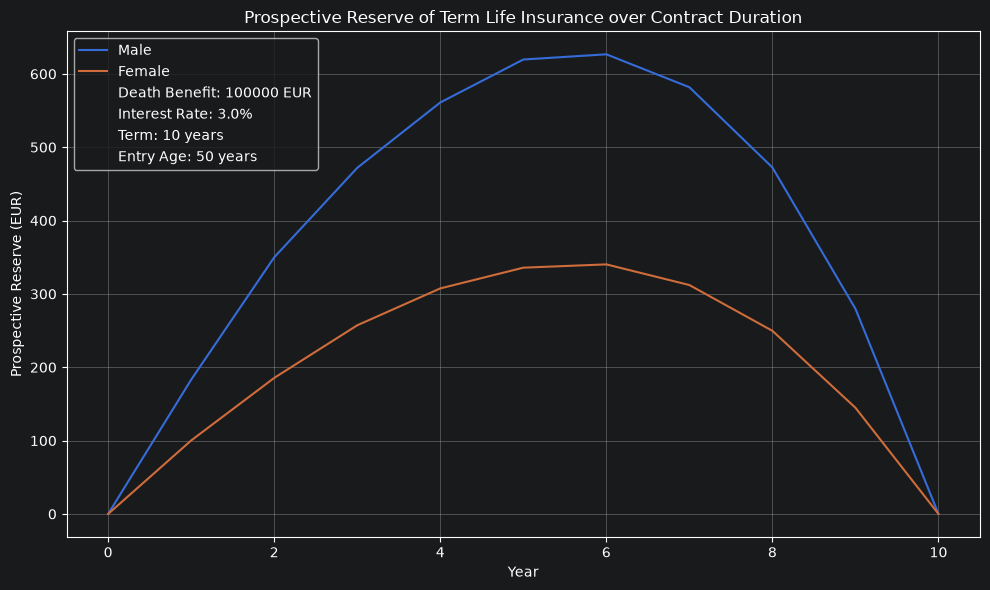

In [7]:
# Visualize results
plt.figure(figsize=(10, 6))

plt.plot(results_reserve_df["year"], results_reserve_df["reserve_male"], label="Male")

plt.plot(results_reserve_df["year"], results_reserve_df["reserve_female"], label="Female")

plt.title(f"Prospective Reserve of Term Life Insurance over Contract Duration")

plt.xlabel("Year")
plt.ylabel("Prospective Reserve (EUR)")

# Create invisible lines to display parameters in legend
plt.axhline(y=0, color='none', label=f"Death Benefit: {DEATH_BENEFIT} EUR")
plt.axhline(y=0, color='none', label=f"Interest Rate: {INTEREST_RATE * 100}%")
plt.axhline(y=0, color='none', label=f"Term: {TERM} years")
plt.axhline(y=0, color='none', label=f"Entry Age: {AGE_INDIVIDUAL} years")

plt.legend()
plt.grid(True)

plt.tight_layout()

# save figure
FIGURE_PATH = (PROJECT_ROOT / "reports" / "figures" / "prospective_reserve_TLI_over_years.png")
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")

plt.show()